# Phase 1 â€” Data: do Coca-Cola and PepsiCo move together?

**What this notebook does.** It loads the daily share prices of the two companies, shows what the raw
data looks like, reports every stock split and dividend in the period, explains how the data was
checked and cleaned, and then answers two simple questions with three charts:

1. Do the two prices move together?
2. Is their relationship stable over the years, or does it slowly drift apart?

**Why this pair.** Coca-Cola (ticker **KO**) and PepsiCo (ticker **PEP**) sell very similar products
to the same customers, so their shares react to much of the same news (consumer spending, sugar and
aluminium costs, the dollar). Pairs trading bets on exactly this: when two related prices drift apart
for a while, they tend to come back together. Before building any strategy we check that the
relationship is really there.

**Words used below**

| Term | Meaning |
|---|---|
| Close price | The last traded price of the day (Yahoo already corrects it for stock splits) |
| Stock split | The company swaps each share for two (2-for-1): the price halves, the value held does not change |
| Dividend | Cash paid by the company to shareholders, here every quarter; on the *ex-date* the price drops by about that amount |
| Adjusted close price | The close price also corrected for dividends, so that a dividend payment does not look like a price drop |
| Daily return | The percentage change of the price from one trading day to the next |
| Correlation | A number between -1 and +1: +1 means the two daily returns always move in the same direction and proportion, 0 means no relation |
| In-sample / out-of-sample | The past we are allowed to study (2000â€“2018) / the later period (2019â€“2026) kept untouched for the final, one-off test |

## 1. Set-up

All the choices of this phase in one place. The dates were fixed in the code (`src/pairs/config.py`)
**before any price was downloaded**, and are the same for every phase of the project.

**Why the sample starts in 2000, although Yahoo has prices back to 1972 for both stocks.**

1. **PepsiCo only became comparable to Coca-Cola at the end of the 1990s.** Until 1997 it also owned
   Pizza Hut, KFC and Taco Bell, spun off as Tricon Global Restaurants (today Yum! Brands) effective
   6 Oct 1997 ([SEC filing](https://www.sec.gov/Archives/edgar/data/0001041061/000104106198000004/0001041061-98-000004.txt));
   its bottling arm was listed separately as Pepsi Bottling Group on 31 Mar 1999
   ([SEC filing](https://www.sec.gov/Archives/edgar/data/0001076405/000107640599000017/0001076405-99-000017.txt)).
   From 2000 both are beverage and snack brand companies. One large change stays inside our sample and
   is worth remembering: PepsiCo merged with Quaker Oats (owner of Gatorade) on 2 Aug 2001
   ([CNN](https://money.cnn.com/2001/08/02/deals/pepsico/)).
2. **Trading worked differently before 2001.** US stocks were quoted in fractions of a dollar (1/8,
   1/16) until the New York Stock Exchange switched to cents on 29 Jan 2001 (Nasdaq on 9 Apr 2001)
   ([The Daily Record](https://thedailyrecord.com/2001/01/29/nyse-goes-totally-decimal-8212-finally/)),
   so trading costs were much higher and not comparable with today's.
3. **The spread of Phase 2 comes from a regression on price levels.** From 1972 to 2018 the adjusted
   prices grow 131 times (KO) and 236 times (PEP), against 2.8 and 4.7 times from 2000: one regression
   over 1972â€“2018 would be dominated by the most recent years.

The start date was fixed in the code before any price was downloaded. Having now seen the 2000â€“2018
data, it **cannot be moved** (for example to 2005, after the early drift seen below): that would be
choosing the sample by looking at the results. The history before 2000 is still shown, as context with
less weight, in section 8.

**We only look at the in-sample period, 3 Jan 2000 â€“ 31 Dec 2018.** The years after that are the final
exam of the strategy: looking at them now, even just at a chart, could influence our choices and would
make that final test dishonest. The brief requires this split for testing (Phase 2 onwards); applying it
to this descriptive phase too is our own, more cautious choice. After the single out-of-sample run at the
end of the project, the same charts are shown on the full 2000â€“2026 period.

In [1]:
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

from pairs.config import PAIR, Settings
from pairs.data import (
    KNOWN_DIVIDEND_ERRORS,
    VALIDATED_FILE,
    correct_dividend_errors,
    fetch_context_prices,
    fetch_corporate_actions,
    fetch_raw_prices,
)
from pairs.explore import (
    adjustment_from_dividends,
    daily_returns,
    largest_moves,
    longest_gaps,
    select_until,
    yearly_correlation,
)
from pairs.logging_setup import configure_logging
from pairs.plots import finish_figure, save_figure

configure_logging()
# Interactive chart in VS Code / Jupyter, plus a static PNG copy that GitHub can display
pio.renderers.default = "plotly_mimetype+png"
settings = Settings.from_env()
figures_dir = settings.results_dir / "figures"
SOURCE = "Source: Yahoo Finance, in-sample period 2000-2018."
COLORS = {"KO": "#c0392b", "PEP": "#1f4e9c"}
NAMES = {"KO": "Coca-Cola (KO)", "PEP": "PepsiCo (PEP)"}

pd.DataFrame(
    [
        (
            "Pair",
            f"{PAIR.ticker_a} (Coca-Cola) and {PAIR.ticker_b} (PepsiCo)",
            "Textbook pair: same sector, same customers",
        ),
        (
            "In-sample (study and tuning)",
            f"{PAIR.start} to {PAIR.in_sample_end}",
            "19 years, enough to estimate every parameter",
        ),
        (
            "Out-of-sample (final test, run once)",
            f"after {PAIR.in_sample_end} to {PAIR.end}",
            "~7.8 years (~29% of the data), not looked at here",
        ),
        ("Price used", "Adjusted close", "A dividend would otherwise look like a price drop"),
        ("Returns", "Simple daily returns", "The intuitive 'percentage change'"),
        ("Missing days", "Dropped, never filled", "Filling would invent a zero return"),
    ],
    columns=["Item", "Choice", "Why"],
).set_index("Item")

,Choice,Why
Item,,
Pair,KO (Coca-Cola) and PEP (PepsiCo),"Textbook pair: same sector, same customers"
In-sample (study and tuning),2000-01-03 to 2018-12-31,"19 years, enough to estimate every parameter"
"Out-of-sample (final test, run once)",after 2018-12-31 to 2026-10-09,"~7.8 years (~29% of the data), not looked at here"
Price used,Adjusted close,A dividend would otherwise look like a price drop
Returns,Simple daily returns,The intuitive 'percentage change'
Missing days,"Dropped, never filled",Filling would invent a zero return


## 2. What the raw data looks like

The download is saved once, exactly as Yahoo sends it (`data/prices_raw.pkl`), so that every number
can be reproduced (Yahoo rewrites its adjusted prices after every new dividend). For each stock and
day it holds six columns: open, high, low, close, adjusted close and volume (number of shares traded).
The first rows:

In [2]:
raw = select_until(fetch_raw_prices(PAIR, settings.data_dir), PAIR.in_sample_end)
raw[["Close", "Adj Close", "Volume"]].head().round(2)

11:49:50 INFO     Loading raw checkpoint C:\Users\gianl\Documents\bsq-pairs-trading\data\prices_raw.pkl

         INFO     Kept 4779 of 6733 rows up to 2018-12-31

Price       Close        Adj Close           Volume          
Ticker         KO    PEP        KO    PEP        KO       PEP
Date                                                         
2000-01-03  28.19  36.88     13.36  18.42  10997000   5298400
2000-01-04  28.22  35.94     13.37  17.95   7308000   4555700
2000-01-05  28.47  35.06     13.49  17.52   9457400   5701900
2000-01-06  28.50  36.62     13.50  18.30   7129200   6863100
2000-01-07  30.38  37.62     14.39  18.80  11474000  10527800

## 3. Stock splits and dividends

Splits and dividends change how past prices must be read, so every one of them in the period is
reported here (source: Yahoo Finance, saved in `data/actions_raw.pkl`).

### 3.1 Stock splits

In [3]:
events = fetch_corporate_actions(PAIR, settings.data_dir)
events = select_until(events.loc[events.index >= pd.Timestamp(PAIR.start)], PAIR.in_sample_end)
splits = events.loc[events["split"] > 0, ["ticker", "split"]].rename(
    columns={"split": "new shares per old share"}
)
splits

         INFO     Loading corporate actions checkpoint                                                             
                  C:\Users\gianl\Documents\bsq-pairs-trading\data\actions_raw.pkl

         INFO     Kept 154 of 216 rows up to 2018-12-31

,ticker,new shares per old share
date,,
2012-08-13,KO,2.0


**One split in 19 years: Coca-Cola, 2-for-1, on 13 Aug 2012.** PepsiCo had none.

**How the split is handled.** We do not adjust anything ourselves: Yahoo already rewrites KO's history
backwards, dividing every price before 13 Aug 2012 by 2 (open, high, low, close and adjusted close),
multiplying the volumes by 2 and dividing the dividend amounts by 2. Without this, KO's price would
show a fake -50% drop on the split day. We check that it is really the case:

In [4]:
split_day = pd.Timestamp("2012-08-13")
around_split = raw.xs("KO", axis=1, level=1).loc[
    "2012-08-08":"2012-08-16", ["Close", "Adj Close", "Volume"]
]
around_split["Close return %"] = 100 * raw[("Close", "KO")].pct_change().loc[around_split.index]
ko_volume = raw[("Volume", "KO")]
volume_check = pd.Series(
    {
        "median daily volume, 3 months before (M shares)": ko_volume.loc[
            "2012-05-13":"2012-08-10"
        ].median()
        / 1e6,
        "median daily volume, 3 months after (M shares)": ko_volume.loc[
            "2012-08-13":"2012-11-13"
        ].median()
        / 1e6,
    }
)
display(around_split.round(2), volume_check.round(1).to_frame("value"))

Price,Close,Adj Close,Volume,Close return %
Date,,,,
2012-08-08,39.78,25.68,8790200,-0.26
2012-08-09,39.62,25.57,9583400,-0.40
2012-08-10,39.40,25.43,40577600,-0.57
2012-08-13,39.30,25.37,8898200,-0.24
2012-08-14,39.38,25.42,10841200,0.20
2012-08-15,39.35,25.40,7692500,-0.08
2012-08-16,39.55,25.53,8824100,0.51


,value
"median daily volume, 3 months before (M shares)",13.4
"median daily volume, 3 months after (M shares)",13.7


On the split day KO moves by -0.24%, an ordinary day, and the traded volume is of the same size
before and after: prices and volumes are consistently split-adjusted. (Over the whole period KO's
largest daily moves are -10.1% and +13.9%, so no other split is hiding in the data.)
The single day of very high volume on Friday 10 August (40.6 million shares, about three times normal)
is not explained here; volume is not used by the strategy, only as evidence in section 4.

Consequence for reading the data: **the KO close of 28.19 on 3 Jan 2000 means about 56.4 dollars on
the market that day, well above PepsiCo's 36.9.** At the start of our sample Coca-Cola was the more
expensive share.

### 3.2 Dividends

Both companies pay a dividend every quarter. The table shows, for each year, how many dividends were
paid, the total in dollars per share (split-adjusted) and the **dividend yield**: the total divided by
the average share price of the year, i.e. the percentage of the price paid out in cash. One record
reported by Yahoo is wrong and is left out here; it is explained in section 3.4.

In [5]:
reported = events.loc[events["dividend"] > 0]  # everything Yahoo reports
wrong = [(pd.Timestamp(e.ex_date), e.ticker) for e in KNOWN_DIVIDEND_ERRORS]
is_wrong = [
    (day, ticker) in wrong for day, ticker in zip(reported.index, reported["ticker"], strict=True)
]
dividends = reported.loc[[not flag for flag in is_wrong]]  # the dividends actually paid
close = raw["Close"]
table = {}
for ticker in ("KO", "PEP"):
    paid = dividends.loc[dividends["ticker"] == ticker, "dividend"]
    by_year = paid.groupby(paid.index.year)
    avg_price = close[ticker].groupby(close.index.year).mean()
    table[(ticker, "number")] = by_year.size()
    table[(ticker, "$ per share")] = by_year.sum().round(3)
    table[(ticker, "yield %")] = (100 * by_year.sum() / avg_price).round(2)
dividend_table = pd.DataFrame(table)
dividend_table.index.name = "year"
dividend_table

KO                        PEP                    
     number $ per share yield % number $ per share yield %
year                                                      
2000      4        0.34    1.23      4       0.555    1.35
2001      4        0.36    1.48      4       0.575    1.25
2002      4        0.40    1.61      4       0.595    1.29
2003      4        0.44    2.00      4       0.630    1.43
2004      4        0.50    2.15      4       0.850    1.66
2005      4        0.56    2.62      4       1.010    1.82
2006      4        0.62    2.83      4       1.160    1.90
2007      4        0.68    2.53      4       1.425    2.09
2008      4        0.76    2.82      4       1.650    2.50
2009      4        0.82    3.36      4       1.775    3.20
2010      4        0.88    3.11      4       1.890    2.93
2011      4        0.94    2.82      4       2.025    3.11
2012      4        1.02    2.75      4       2.128    3.11
2013      4        1.12    2.82      4       2.241    2.79
2014      4        1.22    2.99      4       2.533    2.85
2015      4        1.32    3.20      4       2.764    2.86
2016      4        1.40    3.22      4       2.962    2.86
2017      4        1.48    3.34      4       3.168    2.80
2018      4        1.56    3.44      4       3.589    3.24

11:49:55 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_dividend_yield.png

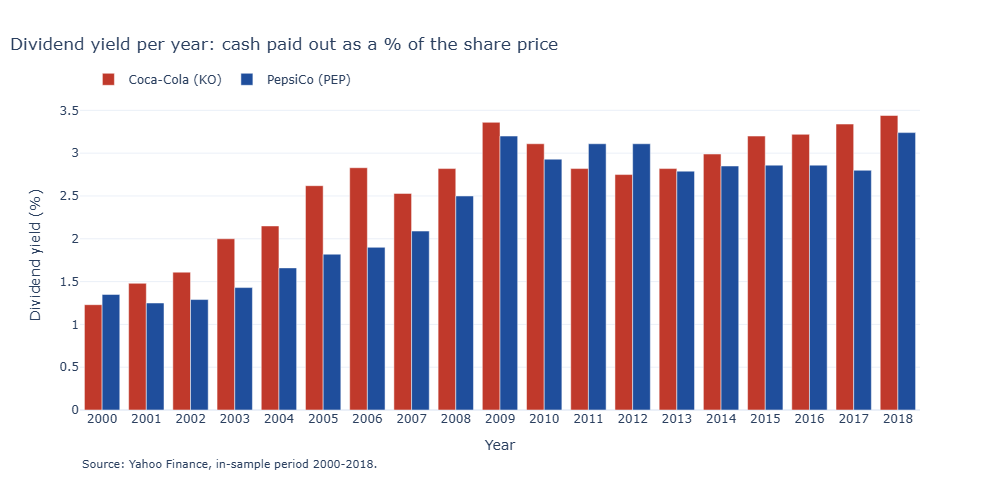

In [6]:
fig = go.Figure()
for ticker in ("KO", "PEP"):
    fig.add_trace(
        go.Bar(
            x=dividend_table.index,
            y=dividend_table[(ticker, "yield %")],
            name=NAMES[ticker],
            marker_color=COLORS[ticker],
        )
    )
finish_figure(
    fig,
    "Dividend yield per year: cash paid out as a % of the share price",
    "Year",
    "Dividend yield (%)",
    SOURCE,
)
fig.update_xaxes(dtick=1)
save_figure(fig, "01_dividend_yield", figures_dir)
fig.show()

### 3.3 How dividends change the prices we use, and a check

On each ex-date the share price drops by about the dividend paid. The adjusted close removes these
drops by scaling down every earlier price, so that the adjusted series measures the **total** return
of holding the share (price change plus dividends). After 19 years of dividends the adjusted price of
January 2000 is only about half of the close:

In [7]:
first, last = raw.index[0], raw.index[-1]
levels = pd.DataFrame(
    {
        "Close": [raw.at[d, ("Close", t)] for d in (first, last) for t in ("KO", "PEP")],
        "Adjusted close": [
            raw.at[d, ("Adj Close", t)] for d in (first, last) for t in ("KO", "PEP")
        ],
    },
    index=pd.MultiIndex.from_product(
        [[first.date(), last.date()], ["KO", "PEP"]], names=["Day", "Ticker"]
    ),
)
levels["Adjusted / close"] = levels["Adjusted close"] / levels["Close"]
levels.round(3)

Close  Adjusted close  Adjusted / close
Day        Ticker                                           
2000-01-03 KO       28.188          13.356             0.474
           PEP      36.875          18.422             0.500
2018-12-31 KO       47.350          37.452             0.791
           PEP     110.480          86.719             0.785

**Check: are Yahoo's adjusted prices explained by the dividends Yahoo reports, and by nothing else?**
We rebuild the adjustment ourselves from Yahoo's dividend list (each price before an ex-date is
multiplied by `1 - dividend / previous close`) and compare it with Yahoo's ratio adjusted / close, over
the whole in-sample period. The largest difference on any day:

In [8]:
rebuild_error = {}
for ticker in ("KO", "PEP"):
    paid = reported.loc[reported["ticker"] == ticker, "dividend"]
    ours = adjustment_from_dividends(close[ticker], paid)
    yahoo = raw[("Adj Close", ticker)] / close[ticker]
    yahoo = yahoo / yahoo.iloc[-1]  # same reference as ours: factor 1 on the last in-sample day
    rebuild_error[ticker] = float((ours / yahoo - 1).abs().max())
pd.Series(rebuild_error, name="largest difference (%)").mul(100).round(4).to_frame()

,largest difference (%)
KO,0.0033
PEP,0.0001


The differences are a few thousandths of a percent (rounding of prices to the cent), so **the
adjusted prices contain the reported dividends and nothing else**. This check proves consistency, not
correctness: if a reported dividend is itself wrong, it is inside the adjusted prices too, and the
check cannot see it. Section 3.4 shows that this happens once.

### 3.4 An error in Yahoo's data: a dividend that was never paid

Listing KO's dividends date by date shows two records in the week of 11 September 2001:

In [9]:
reported.loc["2001-06-01":"2001-12-31"].query("ticker == 'KO'")

,ticker,dividend,split
date,,,
2001-06-13,KO,0.09,0.0
2001-09-10,KO,0.18,0.0
2001-09-17,KO,0.09,0.0
2001-11-28,KO,0.09,0.0


KO paid 0.09 dollars per quarter that year (split-adjusted), and the ex-date of September moved to the
17th because the exchange was closed from the 11th to the 14th. **The 0.18 record of 10 September is a
duplicate of the same dividend at its amount before the 2012 split (0.09 x 2)**, i.e. a split-handling
error in Yahoo's data. It is the only such case in 2000-2018 (no other two dividends of the same stock
are less than 40 days apart). Yahoo applied it to the adjusted prices, which creates a fake gain on
10 September 2001:

In [10]:
error_day = pd.Timestamp("2001-09-10")
prices = select_until(pd.read_pickle(settings.data_dir / VALIDATED_FILE), PAIR.in_sample_end)
fake_gain = pd.Series(
    {
        "Close (price only, no dividend that day)": raw[("Close", "KO")]
        .pct_change()
        .loc[error_day],
        "Yahoo adjusted close (with the wrong dividend)": raw[("Adj Close", "KO")]
        .pct_change()
        .loc[error_day],
        "Our adjusted close (corrected)": prices["KO"].pct_change().loc[error_day],
    }
)
fake_gain.mul(100).round(2).to_frame("KO return on 2001-09-10 (%)")

11:49:58 INFO     Kept 4779 of 6733 rows up to 2018-12-31

,KO return on 2001-09-10 (%)
"Close (price only, no dividend that day)",0.44
Yahoo adjusted close (with the wrong dividend),1.17
Our adjusted close (corrected),0.44


**Correction** (`correct_dividend_errors` in `src/pairs/data.py`, applied before the "validated"
checkpoint): the adjusted KO prices before 10 September 2001 are divided back by the factor Yahoo
applied, so they rise by 0.73% (425 trading days); PepsiCo is untouched and the raw download is kept
exactly as Yahoo sent it. After the correction the return of that day equals the price return, as it
must, and our adjusted prices match the list of dividends **actually paid**:

In [11]:
corrected_error = {}
for ticker in ("KO", "PEP"):
    paid = dividends.loc[dividends["ticker"] == ticker, "dividend"]
    ours = adjustment_from_dividends(close[ticker], paid)
    used = prices[ticker] / close[ticker]
    corrected_error[ticker] = float((ours / (used / used.iloc[-1]) - 1).abs().max())
pd.Series(corrected_error, name="largest difference (%)").mul(100).round(4).to_frame()

,largest difference (%)
KO,0.0033
PEP,0.0001


Because levels of adjusted prices are not the prices people saw at the time, the charts below compare
**growth** (both lines start at 100) and the **movements** of the price ratio, never the raw levels.

## 4. Data cleaning: what was checked, what was removed

Each check below is run on the in-sample data. The result column shows what was found.

In [12]:
adj = raw["Adj Close"]
days_per_year = adj.groupby(adj.index.year).size()
checks = pd.DataFrame(
    [
        ("Missing values (any column)", int(raw.isna().sum().sum())),
        ("Duplicate dates", int(raw.index.duplicated().sum())),
        ("Prices <= 0", int((adj <= 0).sum().sum())),
        ("Days with one stock missing (removed)", int(adj.isna().any(axis=1).sum())),
        ("Trading days per year (min)", int(days_per_year.min())),
        ("Trading days per year (max)", int(days_per_year.max())),
    ],
    columns=["Check", "Result"],
).set_index("Check")
checks

,Result
Check,
Missing values (any column),0
Duplicate dates,0
Prices <= 0,0
Days with one stock missing (removed),0
Trading days per year (min),248
Trading days per year (max),253


**Nothing had to be removed.** A US year has about 252 trading days, so 248â€“253 per year means no
stretch of data is missing. To be sure, the longest pauses between two trading days are listed below:
a normal weekend is 3 days, a long weekend 4; every longer pause matches a real closure of the New York
Stock Exchange.

In [13]:
gaps = longest_gaps(pd.DatetimeIndex(adj.index), 3)
gaps["Reason"] = [
    "Exchange closed 11-14 Sep after the September 11 attacks",
    "New Year's Day, then national day of mourning for President Ford (2 Jan)",
    "Exchange closed 29-30 Oct for Hurricane Sandy",
]
gaps

,from,to,calendar_days,Reason
0,2001-09-10,2001-09-17,7,Exchange closed 11-14 Sep after the September ...
1,2006-12-29,2007-01-03,5,"New Year's Day, then national day of mourning ..."
2,2012-10-26,2012-10-31,5,Exchange closed 29-30 Oct for Hurricane Sandy


**Extreme days.** The six largest one-day moves are listed with two pieces of evidence. A data error
usually jumps and comes straight back the next day, on ordinary volume. A real event keeps most of the
move and is traded on unusually high volume (`volume_vs_median` = volume that day divided by the
stock's typical daily volume).

In [14]:
moves = largest_moves(raw["Close"], raw["Volume"], 6)
moves.round(3)

,date,ticker,return,next_day_return,volume_vs_median
0,2002-10-08,PEP,0.149,0.012,4.952
1,2008-10-13,KO,0.139,-0.075,3.891
2,2008-10-14,PEP,-0.119,-0.058,7.459
3,2008-10-28,KO,0.103,-0.031,2.781
4,2002-07-19,PEP,-0.102,-0.019,4.143
5,2002-10-16,KO,-0.101,-0.028,2.881


All six days have two to five times the normal volume, so many investors really traded at those prices.
Four of them keep their move the next day. The two October 2008 days (KO +13.9% on the 13th, PEP
-11.9% on the 14th) are partly reversed, but they fall in the most violent week of the 2008 financial
crisis, when the whole US market rose about 12% in one day and fell sharply right after. We therefore
treat all six as **real events and keep them**: removing them would make the strategy look safer than
it is.

## 5. The two prices side by side

Both prices start at **100** on the first day: a value of 150 means "the share is worth 50% more than
in January 2000, dividends included". This removes the difference in price levels discussed in
section 3 and shows only how each stock grew.

**How to read it:** if the two lines climb and fall at the same moments, the two stocks react to the
same news. A gap that opens and never closes would be a warning sign.

11:50:02 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_prices_rebased.png

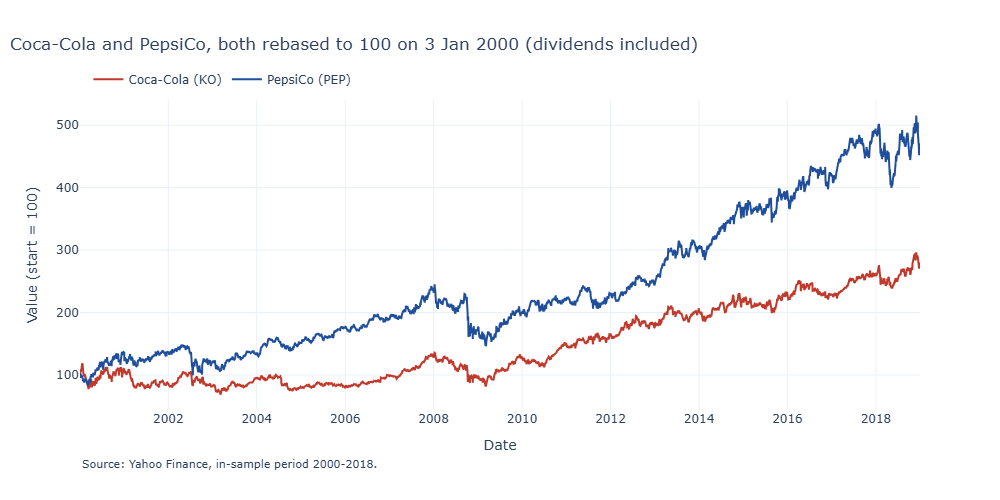

In [15]:
rebased = 100 * prices / prices.iloc[0]  # prices = validated and corrected (section 3.4)

fig = go.Figure()
for ticker in ("KO", "PEP"):
    fig.add_trace(
        go.Scatter(
            x=rebased.index, y=rebased[ticker], name=NAMES[ticker], line={"color": COLORS[ticker]}
        )
    )
finish_figure(
    fig,
    "Coca-Cola and PepsiCo, both rebased to 100 on 3 Jan 2000 (dividends included)",
    "Date",
    "Value (start = 100)",
    SOURCE,
)
save_figure(fig, "01_prices_rebased", figures_dir)
fig.show()

## 6. The ratio between the two prices

The brief asks for the **ratio or the difference** of the two prices. We use the **ratio** KO / PEP:
it is a pure number, while the difference in dollars grows simply because both prices grow over 19
years, even if the relationship itself does not change. As explained in section 3, its *level* depends
on the dividend adjustment; what matters is how it *moves*.

**How to read it:** a ratio that wanders up and down around the dashed line (its 2000â€“2018 average)
means a stable relationship, the situation pairs trading needs. A ratio that trends steadily in one
direction for years means one company is persistently outgrowing the other.

11:50:09 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_price_ratio.png

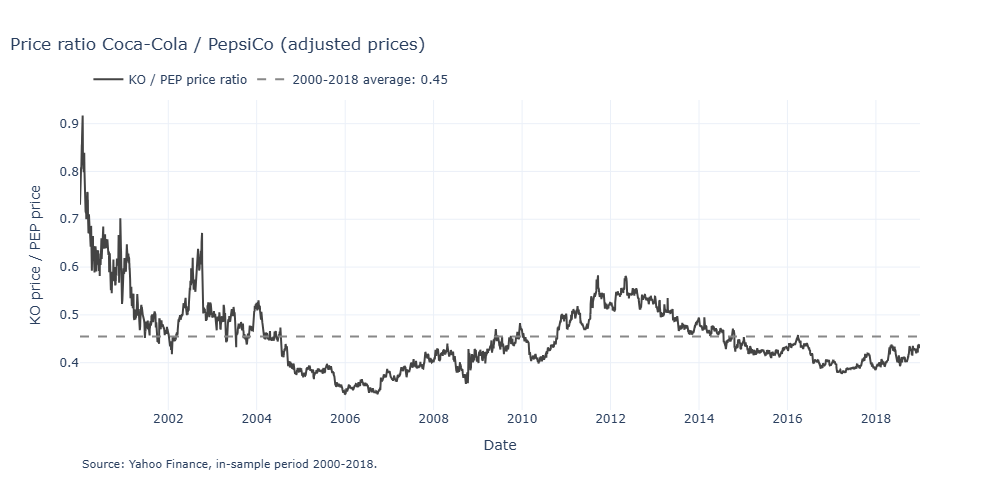

In [16]:
ratio = prices["KO"] / prices["PEP"]

fig = go.Figure()
fig.add_trace(
    go.Scatter(x=ratio.index, y=ratio, name="KO / PEP price ratio", line={"color": "#444444"})
)
fig.add_trace(
    go.Scatter(
        x=[ratio.index[0], ratio.index[-1]],
        y=[ratio.mean()] * 2,
        name=f"2000-2018 average: {ratio.mean():.2f}",
        mode="lines",
        line={"color": "#888888", "dash": "dash"},
    )
)
finish_figure(
    fig, "Price ratio Coca-Cola / PepsiCo (adjusted prices)", "Date", "KO price / PEP price", SOURCE
)
save_figure(fig, "01_price_ratio", figures_dir)
fig.show()

## 7. Do the daily moves agree?

The chart above is about long-term levels. Here we look at day-to-day moves: on a day when Coca-Cola
goes up, does PepsiCo tend to go up too? The **correlation of daily returns** measures this with one
number, and computing it **separately for each calendar year** (about 250 trading days each) shows
whether that link stays the same over time or weakens.

**How to read it:** each bar is one year and the dashed line is the value over the whole period.
Bars of similar height mean a stable link; a year with a much shorter bar is a year in which the two
stocks went more their own way.

11:50:17 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_yearly_correlation.png

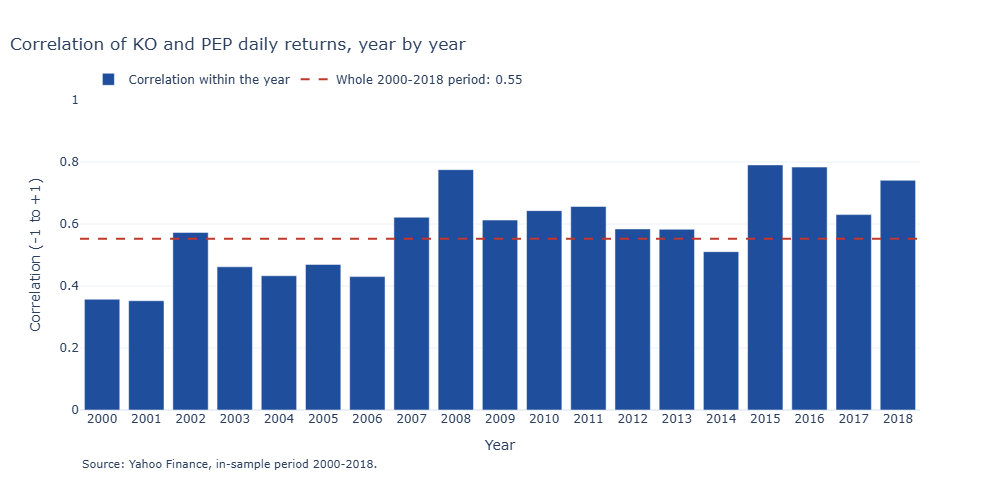

,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018
correlation,0.36,0.35,0.57,0.46,0.43,0.47,0.43,0.62,0.78,0.61,0.64,0.66,0.58,0.58,0.51,0.79,0.78,0.63,0.74


In [17]:
returns = daily_returns(prices)
overall = returns["KO"].corr(returns["PEP"])
by_year = yearly_correlation(returns, "KO", "PEP")

fig = go.Figure()
fig.add_trace(
    go.Bar(x=by_year.index, y=by_year, name="Correlation within the year", marker_color="#1f4e9c")
)
fig.add_trace(
    go.Scatter(
        x=[by_year.index[0] - 0.5, by_year.index[-1] + 0.5],
        y=[overall] * 2,
        name=f"Whole 2000-2018 period: {overall:.2f}",
        mode="lines",
        line={"color": "#c0392b", "dash": "dash"},
    )
)
finish_figure(
    fig,
    "Correlation of KO and PEP daily returns, year by year",
    "Year",
    "Correlation (-1 to +1)",
    SOURCE,
)
fig.update_yaxes(range=[0, 1])
fig.update_xaxes(dtick=1)
save_figure(fig, "01_yearly_correlation", figures_dir)
fig.show()

by_year.round(2).to_frame().T

## 8. Before 2000: context, with less weight

The brief asks whether the relationship drifts "over the decades". Our sample covers two; Yahoo has
prices for both stocks from **1 June 1972** (PepsiCo's first day on Yahoo; Coca-Cola starts in 1962).
This history lies *before* the in-sample period, so looking at it cannot contaminate the final test,
and nothing in the project is estimated on it. It is given **less weight** for the three reasons of
section 1: PepsiCo was a different company (restaurants until 1997, bottlers until 1999), prices were
quoted in fractions of a dollar, and price levels were 100-200 times lower.

The same checks as for the main data (saved in `data/prices_context_raw.pkl`):

In [18]:
context_raw = fetch_context_prices(PAIR, settings.data_dir)
context_adj = context_raw["Adj Close"][["KO", "PEP"]]
both_quoted = context_adj.notna().all(axis=1)
context_checks = pd.DataFrame(
    [
        ("Days with only KO quoted (before PEP's first day, removed)", int((~both_quoted).sum())),
        ("Days with both stocks", int(both_quoted.sum())),
        ("Missing values on those days", int(context_raw.loc[both_quoted].isna().sum().sum())),
        ("Duplicate dates", int(context_raw.index.duplicated().sum())),
        ("First common day", context_adj.loc[both_quoted].index[0].date()),
    ],
    columns=["Check", "Result"],
).set_index("Check")
context_checks

11:50:20 INFO     Loading context checkpoint C:\Users\gianl\Documents\bsq-pairs-trading\data\prices_context_raw.pkl

,Result
Check,
"Days with only KO quoted (before PEP's first day, removed)",2599
Days with both stocks,6970
Missing values on those days,0
Duplicate dates,0
First common day,1972-06-01


**Splits and dividends before 2000.** Both companies split their shares several times; Yahoo applies
all of them backwards, as in 2012. Among the dividends there is one special record: on 7 Oct 1997
Yahoo lists a "dividend" of 3.20 dollars per PepsiCo share, which is the value of the Tricon shares
distributed in the spin-off (one Tricon share per ten PepsiCo shares). Treating a spin-off as a cash
distribution is the standard way to adjust prices for it. The amount is plausible: Tricon traded at
about 31 dollars in its first days, i.e. about 3.1 dollars per PepsiCo share (not verified to the
cent).

In [19]:
all_events = fetch_corporate_actions(PAIR, settings.data_dir)
before = all_events.loc[
    (all_events.index >= pd.Timestamp("1972-06-01")) & (all_events.index < pd.Timestamp(PAIR.start))
]
context_splits = before.loc[before["split"] > 0, ["ticker", "split"]].rename(
    columns={"split": "new shares per old share"}
)
spin_off = before.loc[
    (before["ticker"] == "PEP") & (before.index == pd.Timestamp("1997-10-07")),
    ["ticker", "dividend"],
]
display(
    context_splits,
    before.loc[before["dividend"] > 0].groupby("ticker").size().to_frame("dividends 1972-1999"),
    spin_off.rename(columns={"dividend": "Tricon spin-off recorded as a dividend ($)"}),
)

         INFO     Loading corporate actions checkpoint                                                             
                  C:\Users\gianl\Documents\bsq-pairs-trading\data\actions_raw.pkl

,ticker,new shares per old share
date,,
1977-05-31,PEP,3.0
1977-06-01,KO,2.0
1986-05-29,PEP,3.0
1986-07-01,KO,3.0
1990-05-14,KO,2.0
1990-09-05,PEP,3.0
1992-05-12,KO,2.0
1996-05-13,KO,2.0
1996-05-29,PEP,2.0


,dividends 1972-1999
ticker,
KO,111
PEP,112


,ticker,Tricon spin-off recorded as a dividend ($)
date,,
1997-10-07,PEP,3.2


**Extreme days before 2000**, with the same evidence as in section 4:

In [20]:
common = context_raw.loc[both_quoted]
largest_moves(common["Close"][["KO", "PEP"]], common["Volume"][["KO", "PEP"]], 6).round(3)

,date,ticker,return,next_day_return,volume_vs_median
0,1987-10-19,KO,-0.247,0.197,7.427
1,1987-10-20,KO,0.197,0.130,10.815
2,1998-09-01,PEP,0.161,-0.041,2.699
3,1982-12-14,PEP,-0.143,-0.025,16.893
4,1987-10-21,KO,0.130,-0.018,6.984
5,1998-08-31,PEP,-0.112,0.161,2.497


The three KO days of 19-21 October 1987 are the stock market crash of "Black Monday" and the rebound
after it, on 7-11 times normal volume. PepsiCo's -14.3% of 14 December 1982 traded on 17 times normal
volume and kept its level, so it is a real company event (its cause is not investigated here). The pair
of PepsiCo days of 31 August - 1 September 1998 (-11.2% then +16.1%) falls in a market-wide crash and
rebound, but the second move is larger than the first and the volume only 2.5-2.7 times normal: we
**cannot rule out a data problem** there. It has no effect on the project, since this period is only
shown as context.

**The ratio and the correlation over five decades.** To compare the two periods on one chart, the
history before 2000 is joined to the in-sample data, with the same dividend correction of section 3.4
applied to it (the wrong dividend of 2001 also lowered every earlier KO adjusted price).

         INFO     Removed wrong KO dividend of 2001-09-10 00:00:00 (factor 0.99276)

11:50:24 INFO     Saved figure C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_context_ratio.png

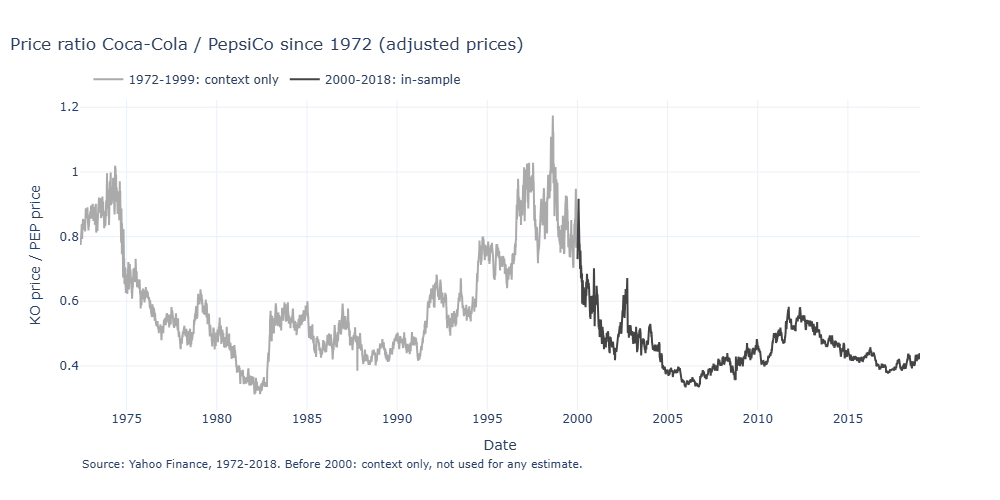

11:50:31 INFO     Saved figure                                                                                     
                  C:\Users\gianl\Documents\bsq-pairs-trading\results\figures\01_context_correlation.png

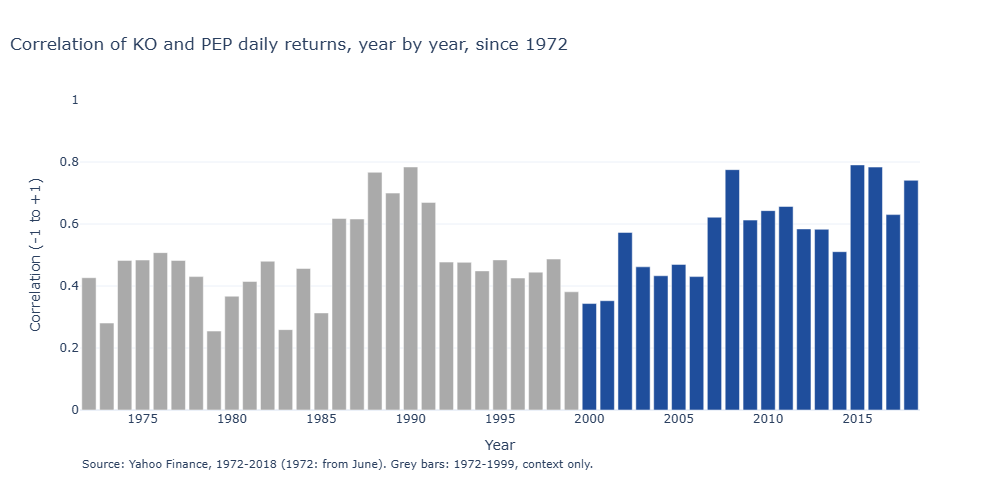

,value
Correlation of daily returns 1972-1999,0.50
Correlation of daily returns 2000-2018,0.55
Ratio KO/PEP: lowest before 2000,0.31
Ratio KO/PEP: highest before 2000,1.17


In [21]:
long_raw = pd.concat([common, raw])
long_prices = correct_dividend_errors(
    long_raw["Adj Close"][["KO", "PEP"]], long_raw, KNOWN_DIVIDEND_ERRORS
)
long_ratio = long_prices["KO"] / long_prices["PEP"]
long_by_year = yearly_correlation(daily_returns(long_prices), "KO", "PEP")
in_sample_days = long_prices.index >= pd.Timestamp(PAIR.start)

fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=long_ratio.index[~in_sample_days],
        y=long_ratio[~in_sample_days],
        name="1972-1999: context only",
        line={"color": "#aaaaaa"},
    )
)
fig.add_trace(
    go.Scatter(
        x=long_ratio.index[in_sample_days],
        y=long_ratio[in_sample_days],
        name="2000-2018: in-sample",
        line={"color": "#444444"},
    )
)
finish_figure(
    fig,
    "Price ratio Coca-Cola / PepsiCo since 1972 (adjusted prices)",
    "Date",
    "KO price / PEP price",
    "Source: Yahoo Finance, 1972-2018. Before 2000: context only, not used for any estimate.",
)
save_figure(fig, "01_context_ratio", figures_dir)
fig.show()

fig = go.Figure()
fig.add_trace(
    go.Bar(
        x=long_by_year.index,
        y=long_by_year,
        marker_color=[
            "#aaaaaa" if year < PAIR.start.year else "#1f4e9c" for year in long_by_year.index
        ],
        name="Correlation within the year (grey: context before 2000)",
    )
)
finish_figure(
    fig,
    "Correlation of KO and PEP daily returns, year by year, since 1972",
    "Year",
    "Correlation (-1 to +1)",
    "Source: Yahoo Finance, 1972-2018 (1972: from June). Grey bars: 1972-1999, context only.",
)
fig.update_yaxes(range=[0, 1])
save_figure(fig, "01_context_correlation", figures_dir)
fig.show()

context_returns = daily_returns(long_prices.loc[~in_sample_days])
context_overall = context_returns["KO"].corr(context_returns["PEP"])
pd.Series(
    {
        "Correlation of daily returns 1972-1999": context_overall,
        "Correlation of daily returns 2000-2018": overall,
        "Ratio KO/PEP: lowest before 2000": long_ratio[~in_sample_days].min(),
        "Ratio KO/PEP: highest before 2000": long_ratio[~in_sample_days].max(),
    }
).round(2).to_frame("value")

**How to read it.** Before 2000 the ratio does not oscillate quickly around one level: it moves in
**long waves lasting about a decade**. the ratio rises to about 1.0 in 1974, then Coca-Cola
loses ground until 1982 (low of 0.31), gains it back and more until 1998 (high of 1.17), then loses it again until about 2005,
which is the drift already seen at the start of our sample. The correlation of daily returns before
2000 is a little lower (0.50 against 0.55) and varies more from year to year (from 0.25 to 0.78).
With the caveats above, this suggests that the two prices are linked day to day, but that their
relative level can drift for many years before it comes back: a warning for any strategy that expects
the spread to revert within weeks or months.

## 9. What we learn

**About the data**

- 4,779 trading days (3 Jan 2000 â€“ 31 Dec 2018), nothing missing, nothing removed; the longest pauses
  are real closures of the exchange and the extreme days are real market events.
- One stock split (Coca-Cola, 2-for-1, 13 Aug 2012), correctly handled by Yahoo. 152 quarterly
  dividends (76 per company), all reported above.
- **One error in Yahoo's data, found and corrected**: a KO dividend of 10 Sep 2001 that was never paid
  (a duplicate at its pre-split amount). Left in, it would add a fake +0.73% gain to KO on one day.
  This was found by listing dividends one by one, not by the consistency check, which could not see it.

**About the relationship**

- **The two stocks are linked, and increasingly so.** The correlation of daily returns is 0.55 over
  2000â€“2018, never below 0.3 in any year, and it rises over time: about 0.35 in 2000â€“01, about 0.45 in
  2003â€“06, between 0.6 and 0.8 after 2007.
- **The relationship is not stable over the whole period.** In January 2000 Coca-Cola was the more
  expensive share (about 56 dollars against 37) and the price ratio starts high (0.73, with a peak of
  0.9 in early 2000). Between 2000 and 2004 Coca-Cola steadily loses this premium and the ratio falls to
  about 0.45: a drift, not an oscillation. **After 2004 the ratio moves between 0.34 and 0.58 and crosses
  its average again and again**, which is the behaviour pairs trading needs.

**Before 2000 (context, less weight)**

- From 1972 to 1999 the daily link is similar (correlation 0.50), but the price ratio moves in **long
  waves of about a decade** (high near 1.0 in 1974, low of 0.31 in 1982, high of 1.17 in 1998). The
  relative level of the two stocks can drift for years before coming back.

**What this means for the next phases**

- A single hedge ratio estimated once on the whole 2000â€“2018 period will be pulled by the early drift,
  and the long history warns that drifts of several years are normal for this pair.
  The spread built from it must therefore be **checked, not assumed** (chart, how often it crosses its
  mean) in Phase 2, and the stability of the relationship over time is exactly what Phase 3 tests.

**What I am unsure about**

- I did not investigate *why* Coca-Cola lost ground in 2000â€“2004 (a commonly cited reason is its very
  high valuation at the end of the 1990s, but I have not verified it): the data shows the drift, not
  its cause.


## 10. Checks

Every number shown above is verified here; if anything changes (data, code), the notebook stops
with an error instead of silently showing different results. The automated test suite runs this
notebook from top to bottom.

In [22]:
# No out-of-sample data, nothing missing, nothing removed
for frame in (raw, events, prices):
    assert frame.index.max() <= pd.Timestamp(PAIR.in_sample_end), "out-of-sample data leaked in"
assert checks["Result"].iloc[:4].sum() == 0, "a cleaning check found a problem"
assert len(prices) == len(raw), "rows were dropped"
assert gaps["calendar_days"].max() == 7

# Splits and dividends: every event reported, adjusted prices fully explained by dividends
assert splits["ticker"].tolist() == ["KO"] and splits.index[0] == pd.Timestamp("2012-08-13")
assert len(reported) == 153 and len(dividends) == 152  # one wrong record removed
assert (dividends["ticker"] == "KO").sum() == 76 and (dividends["ticker"] == "PEP").sum() == 76
assert (dividend_table[("KO", "number")] == 4).all() and (
    dividend_table[("PEP", "number")] == 4
).all()
assert abs(raw[("Close", "KO")].pct_change().loc[split_day]) < 0.01  # no fake -50% on the split day
assert max(rebuild_error.values()) < 1e-4, rebuild_error  # Yahoo consistent with its own list
assert max(corrected_error.values()) < 1e-4, corrected_error  # ours consistent with dividends paid
assert abs(fake_gain.iloc[2] - fake_gain.iloc[0]) < 1e-4  # fake gain removed
assert fake_gain.iloc[1] - fake_gain.iloc[0] > 0.007  # it was there (+0.73%)

# Expected values, recorded on 10 Oct 2026 from the versioned data checkpoints
assert len(prices) == 4779, len(prices)
assert (
    abs(raw.at[first, ("Close", "KO")] - 28.19) < 0.01
)  # i.e. ~56.4 dollars before the 2012 split
assert 2 * raw.at[first, ("Close", "KO")] > raw.at[first, ("Close", "PEP")]  # KO above PEP in 2000
assert abs(overall - 0.552) < 0.001, overall
assert abs(ratio.mean() - 0.454) < 0.001, ratio.mean()
assert by_year.min() > 0.3, "correlation never collapses below 0.3 in any year"
assert len(returns) == len(prices) - 1
assert by_year.index.tolist() == list(range(2000, 2019))
# Context before 2000: only before the sample, same correction, matches the in-sample data exactly
assert common.index.max() < pd.Timestamp(PAIR.start) and len(common) == 6970
assert common.index[0] == pd.Timestamp("1972-06-01")
assert len(context_splits) == 9
assert abs(spin_off["dividend"].iloc[0] - 3.2) < 1e-9
assert (long_prices.loc[in_sample_days] - prices).abs().max().max() < 1e-9
assert abs(context_overall - 0.50) < 0.005, context_overall
assert (
    abs(long_ratio[~in_sample_days].min() - 0.31) < 0.005
    and abs(long_ratio[~in_sample_days].max() - 1.17) < 0.005
)

for name in (
    "01_prices_rebased",
    "01_price_ratio",
    "01_yearly_correlation",
    "01_dividend_yield",
    "01_context_ratio",
    "01_context_correlation",
):
    assert (figures_dir / f"{name}.png").exists(), name